# STATE Codex r2 — 01 Administered drug dose

Run All invokes the source pipeline with `--force`: it recalculates the selected investigation from verified public inputs. Existing downloads can be reused after verification; derived result tables are not a substitute for the default calculation. The completed execution runs on exxact05. Use the documented Python environment and allow the source downloads, CPU time and disk space on a cold run.

The notebooks distinguish measured outcomes from investigations that originally stopped before scoring. For those stops, the reproduced objects are input levels, eligibility, resource diagnostics and the recorded decision; no performance curve is invented. Original results are comparison targets and historical evidence only. Reconstructed choices and numerical differences remain explicit.

See the [original report](../originals/REPORT.md), [candidate ledger](../originals/supporting/audit/candidate_axis_ledger.csv), [public sources](../methods/sources.json) and [pipeline](../methods/run_pipeline.py).

## 1. Data acquisition

The original dose sequence uses the official five-context test lists and three fixed doses. A8 consumes released ST-SE few-shot scores; A10 consumes the separately pinned ST-HVG zero-shot scores. A10R constructs the fixed basal-expression reference from original observed-DE reference means. These are released-output analyses, not new neural inference.

In [1]:
from pathlib import Path
import importlib.util,json,sys
import numpy as np
import pandas as pd
from IPython.display import display,JSON,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'methods/replogle.py').is_file() and (p/'originals/REPORT.md').is_file())
spec=importlib.util.spec_from_file_location('state_codex_r2_notebook',ROOT/'notebooks/shared.py')
wf=importlib.util.module_from_spec(spec);spec.loader.exec_module(wf)
pd.set_option('display.max_colwidth',100);pd.set_option('display.max_rows',100)
manifest=wf.read_json(ROOT,'methods/sources.json')
sources=pd.DataFrame(manifest['inputs'])
display(sources[['path','bytes','sha256','url']])
if manifest.get('remote_observations'):
    display(Markdown('**Pinned observation-only source objects used for Replogle cell counts**'))
    display(pd.DataFrame(manifest['remote_observations']))
wf.source_functions(ROOT,'methods/acquire.py',['main'])
print('Manifest public input records:',len(sources))
print('The next cell executes actual source calculation for this investigation.')


,path,bytes,sha256,url
0,metadata/generalization.toml,150875,eac16fb06052dec9d6842dfae04d5ca693b847e3432f719a975adce205707783,https://raw.githubusercontent.com/ArcInstitute/state/da4178c930dc917dac6b56faf10a33e21bd8e905/st...
1,metadata/depmap_24q4_protein_coding_tpm_logp1.csv,506628654,2a71dc94110efcc0221eae821bb93a9f03b54bea16f005818911a09d33383d56,https://ndownloader.figshare.com/files/51065489
2,metadata/depmap_24q4_model.csv,645696,b7a0c1385e6cef30132b56aff61f1261d11e3f490490b355c430d32ee0dbdcfa,https://ndownloader.figshare.com/files/51065297
3,metadata/hpa_rna_celline.tsv.zip,205861141,e5b11779308c2720cfe89d9cb19932ad4c0c3fea0fa37e8c61a14d501995852a,https://www.proteinatlas.org/download/tsv/rna_celline.tsv.zip
4,ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_pred_de.csv,344243692,230ac1f1f8342d0c7f563166b6e8f9afeae6a02a62d0b737fda64168dde49ba0,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
5,ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_real_de.csv,343530568,a367d89432c430f6bef3d3efd23c0a543144c1c55bb94e64c818c97de2cbd1dd,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
6,ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv,528013,eaf22cc6169fa98ab90913366529db232ac2109fe421599f66d47b14ffd183b3,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
7,ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_pred_de.csv,380905134,fd3422f18087eaf8357112bc0fd87faa8f95ed2a9ad95f0e7c4107d52754a9ca,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
8,ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_real_de.csv,380988038,68fcb087841310e0e435b1bf63f1dbd69fc73c849d31a288f01d9d7ce40982ff,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
9,ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv,568100,372db67f297565e5542cac1bda688586c07e03e92a999bea953a9df812ba5317,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...


**Pinned observation-only source objects used for Replogle cell counts**

,path,url,bytes,sha256,evidence
0,ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/adata_real.h5ad,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...,3079506036,6951f4bffb532950c447e8dc300b2f42ab381c854273327f8cd38b84cfa4eb42,Pinned original release; observation-only range extraction
1,ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/adata_real.h5ad,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...,3012265108,9df1a21e3b159fa3900a32dd8bd6b4d6dd8750838014d1d3997932d7cedc9673,Pinned original release; observation-only range extraction
2,ST-SE-Replogle/zeroshot/hepg2/eval_best.ckpt/adata_real.h5ad,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...,1577727376,75f79feff37c4334559ea88c1e2a27acd306eb7dee5a2e25f37c4860014ca2b9,Pinned original release; observation-only range extraction
3,ST-SE-Replogle/zeroshot/rpe1/eval_best.ckpt/adata_real.h5ad,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...,2837025870,f3363768db24b7eee9cb55507443366f8e15b6f9e5731ac415f533b757a5b5b1,Pinned original release; observation-only range extraction


**Executed implementation:** `methods/acquire.py::main`

def main():
    ap=argparse.ArgumentParser();ap.add_argument('--root',type=Path,required=True);ap.add_argument('--reuse',type=Path);ap.add_argument('--manifest-only',action='store_true');ap.add_argument('--refresh-manifest',action='store_true');a=ap.parse_args();r=a.root.resolve()
    p=r/'methods/sources.json';m=json.loads(p.read_text()) if p.exists() and not a.refresh_manifest else manifest(r)
    if a.manifest_only:return
    reuse={}
    if a.reuse:
        for x in json.loads((a.reuse/'methods/sources.json').read_text())['inputs']:reuse[x['sha256']]=a.reuse/'inputs'/x['path']
    def one(x):
        p=r/'inputs'/x['path'];p.parent.mkdir(parents=True,exist_ok=True)
        if p.exists() and p.stat().st_size==x['bytes'] and sha(p)==x['sha256']:return {**x,'verified':True,'route':'existing'}
        q=reuse.get(x['sha256'])
        if q and q.exists() and q.stat().st_size==x['bytes'] and sha(q)==x['sha256']:
            p.symlink_to(q.resolve());print('REUSE',x['path'],flush=True);return {**x,'verified':True,'route':'identical_sha256_symlink'}
        tmp=p.with_name(p.name+'.part')
        for attempt in range(4):
            try:
                with urllib.request.urlopen(x['url'],timeout=180) as src,tmp.open('wb') as dst:
                    for b in iter(lambda:src.read(8*1024*1024),b''):dst.write(b)
                assert tmp.stat().st_size==x['bytes'],(tmp.stat().st_size,x['bytes'])
                assert sha(tmp)==x['sha256'],'Source checksum mismatch'
                os.replace(tmp,p);print('VERIFIED',x['path'],x['bytes'],flush=True)
                return {**x,'verified':True,'route':'public_download'}
            except Exception:
                if attempt==3:raise
                time.sleep(2*(attempt+1))
    with concurrent.futures.ThreadPoolExecutor(max_workers=2) as pool:done=list(pool.map(one,m['inputs']))
    (r/'inputs/DOWNLOAD_RECEIPT.json').write_text(json.dumps(dict(source_manifest_sha256=sha(r/'methods/sources.json'),inputs=done),indent=2)+'\n')

Manifest public input records: 49
The next cell executes actual source calculation for this investigation.


## 2. Processing

Rebuild the cohort from the intersection of official test lists, enforce each drug’s complete 0.05/0.5/5 µM triplet, join released scores, and aggregate original metadata for condition controls. The original count/QC helper was not recovered; its explicit reconstruction and effect on adjusted estimates are reported in the execution receipts.

In [2]:
pipeline=wf.run_pipeline(ROOT,'dose')
wf.source_functions(ROOT,'methods/tahoe.py',['parse','cohort','controls','scores'])
cohort=wf.read_csv(ROOT,'computed/tahoe/cohort.csv')
display(cohort.head(12));display(JSON(wf.read_json(ROOT,'computed/tahoe/cohort_summary.json')))
wf.source_receipts(ROOT,['tahoe_controls','tahoe_analysis'])


Calculating the original source workflow for dose ; source files are verified before reuse.


Calculating from source inputs: tahoe_analysis


TAHOE A8


TAHOE A10


TAHOE A9


<IPython.core.display.JSON object>

... (10 outputs left out)

**Calculated stage:** tahoe_controls

<IPython.core.display.JSON object>

**Calculated stage:** tahoe_analysis

<IPython.core.display.JSON object>

## 3. Axis

The input-side feature is negative log10 administered dose. It is known from the experiment before prediction outcomes. The earlier A7 draft had a sign contradiction and stopped after schema/initial-row inspection; its contract and decision are preserved without a fabricated A7 result.

In [3]:
display(cohort[['dose','weakness','dose_level']].drop_duplicates().sort_values('dose_level'))
display(JSON(wf.read_json(ROOT,'originals/supporting/audit/axis/frozen_axis_A7_dose_official.json')))
display(JSON(wf.read_json(ROOT,'computed/tahoe/A7_contract_diagnostic.json')))
wf.original_rows(ROOT,['A7'])


,dose,weakness,dose_level
2,5.00,-0.69897,1
1,0.50,0.30103,2
0,0.05,1.30103,3


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

,candidate_id,axis,status,decision_reason,next_action
8,A7,administered dose on ST-HVG few-shot,invalid,written success criterion had a sign contradiction detected after only schema/initial-row inspec...,retired without reinterpretation


These are attributed original decisions, not new adjudications.


,candidate_id,axis,hypothesis_source,prospective_feature,mechanism,required_controls,status,decision_reason,next_action
8,A7,administered dose on ST-HVG few-shot,protocol rescue candidate,negative log dose,weak responses approach the measurement floor,drug; context; nDE; cell counts,invalid,written success criterion had a sign contradiction detected after only schema/initial-row inspec...,retired without reinterpretation


## 4. Levels and eligibility

Level1 is5 µM, level2 is0.5 µM, and level3 is0.05 µM. Actual finite-score exclusions are listed by checkpoint; the complete input cohort is constructed before those metric checks. No dose or subgroup is selected to improve the result.

In [4]:
for name in ['A8','A10']:
    units=wf.read_csv(ROOT,f'computed/tahoe/{name}_units.csv')
    excluded=wf.read_csv(ROOT,f'computed/tahoe/{name}_excluded_scores.csv')
    display(Markdown('**'+name+' finite measurements**'))
    display(units.groupby(['dose_level','dose']).agg(units=('drug','size'),drugs=('drug','nunique'),contexts=('context','nunique')))
    display(excluded)


**A8 finite measurements**

,,units,drugs,contexts
dose_level,dose,,,
1,5.00,995,199,5
2,0.50,994,199,5
3,0.05,995,199,5


,context,drug,dose,unit,weakness,dose_level,score,n_de,n_treated,mito,gene_mean,umi_mean,n_control
0,PANC-1,Encorafenib,0.5,uM,0.30103,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**A10 finite measurements**

,,units,drugs,contexts
dose_level,dose,,,
1,5.00,995,199,5
2,0.50,994,199,5
3,0.05,995,199,5


,context,drug,dose,unit,weakness,dose_level,score,n_de,n_treated,mito,gene_mean,umi_mean,n_control
0,PANC-1,Encorafenib,0.5,uM,0.30103,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Model / released scores

The official signed-LFC Spearman score uses significant real-DE genes, with Fisher-z for regression. A10R predicts ranks from negative basal reference-expression ranks and evaluates on the same example’s observed LFC. The displayed rows and reference calculations come from the original public files.

In [5]:
wf.source_functions(ROOT,'methods/tahoe.py',['reference'])
a10=wf.read_csv(ROOT,'computed/tahoe/A10_units.csv')
reference=wf.read_csv(ROOT,'computed/tahoe/basal_reference_scores.csv')
display(a10[['context','drug','dose','score','n_de','n_treated','n_control','reference_score']].head(12))
display(reference.head(12))


**Executed implementation:** `methods/tahoe.py::reference`

def reference(root,co):
    rows=[];sources=[]
    for c,stem in CELLS.items():
        p=checked(root,f'ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/{stem}_real_de.csv');sources.append(p)
        d=pd.read_csv(p,usecols=['target','feature','reference_mean','fold_change','fdr'])
        keep={(r.drug,r.dose) for r in co[co.context==c].itertuples()}
        for target,g in d.groupby('target',sort=True):
            drug,dose,_=parse(target)
            if (drug,dose) not in keep:continue
            g=g[(g.fdr<.05)&np.isfinite(g.reference_mean)&np.isfinite(g.fold_change)&(g.fold_change>0)]
            value=float(spearmanr(-np.log1p(g.reference_mean),np.log2(g.fold_change)).statistic) if len(g)>=20 else np.nan
            rows.append(dict(context=c,drug=drug,dose=dose,reference_score=value,n_reference_features=len(g)))
    d=pd.DataFrame(rows);d.to_csv(root/'computed/tahoe/basal_reference_scores.csv',index=False);return d,sources

,context,drug,dose,score,n_de,n_treated,n_control,reference_score
0,C32,(R)-Verapamil (hydrochloride),0.05,0.216232,320.0,2180.0,4178.0,0.597530
1,C32,(R)-Verapamil (hydrochloride),0.50,0.497184,427.0,1233.0,5082.0,0.320843
2,C32,(R)-Verapamil (hydrochloride),5.00,0.299367,531.0,4124.0,8290.0,0.691848
3,C32,(S)-Crizotinib,0.05,0.424693,526.0,1974.0,1662.0,-0.254633
4,C32,(S)-Crizotinib,0.50,0.204427,220.0,1445.0,3763.0,-0.252057
5,C32,(S)-Crizotinib,5.00,0.293413,283.0,1015.0,2165.0,-0.120118
6,C32,8-Hydroxyquinoline,0.05,0.473447,289.0,1657.0,4178.0,0.660928
7,C32,8-Hydroxyquinoline,0.50,0.587561,359.0,1595.0,5082.0,0.439746
8,C32,8-Hydroxyquinoline,5.00,0.408025,617.0,3863.0,8290.0,0.672016
9,C32,APTO-253,0.05,0.232420,756.0,1521.0,4343.0,0.872017


,context,drug,dose,reference_score,n_reference_features
0,C32,(R)-Verapamil (hydrochloride),0.05,0.597530,320
1,C32,(R)-Verapamil (hydrochloride),0.50,0.320843,427
2,C32,(R)-Verapamil (hydrochloride),5.00,0.691848,531
3,C32,(S)-Crizotinib,0.05,-0.254633,526
4,C32,(S)-Crizotinib,0.50,-0.252057,220
5,C32,(S)-Crizotinib,5.00,-0.120118,283
6,C32,8-Hydroxyquinoline,0.05,0.660928,289
7,C32,8-Hydroxyquinoline,0.50,0.439746,359
8,C32,8-Hydroxyquinoline,5.00,0.672016,617
9,C32,APTO-253,0.05,0.872017,756


## 6. Curves, controls and diagnostics

Drug-block resampling retains each drug’s contexts/doses. The code shows the raw/adjusted model, recomputed dose curves and paired reference comparison. Original metadata aggregation details are incomplete, so adjusted-control differences are shown without tuning. The separate A9 mitochondrial candidate is reproduced in notebook04.

**Executed implementation:** `methods/common.py::fisher`

def fisher(x):return np.arctanh(np.clip(np.asarray(x,float),-1+1e-7,1-1e-7))

**Executed implementation:** `methods/common.py::cluster_fit`

def cluster_fit(d,y,x,cluster,adjust=(),fixed=(),cluster_fixed=False,draws=10000,seed=20260715):
    """OLS and paired cluster-resampling percentile CI via exact sufficient stats.

    When cluster_fixed=True, first remove the cluster mean. Resampling duplicated
    clusters is equivalent to giving that cluster an integer frequency weight.
    Axis standardization is fixed on the original analyzed rows, not redefined
    within each bootstrap draw. No historical estimates enter this function.
    """
    cols=[y,x,cluster,*adjust,*fixed];d=d.dropna(subset=cols).copy()
    X=[np.ones(len(d)),zscore(d[x])];names=['intercept',x]
    for c in adjust:
        v=np.asarray(d[c],float)
        if np.std(v)>0:X.append(zscore(v));names.append(c)
    for c in fixed:
        for val in sorted(d[c].unique())[1:]:X.append((d[c]==val).astype(float).values);names.append(f'{c}={val}')
    X=np.column_stack(X);Y=d[y].to_numpy(float)
    groups=sorted(d[cluster].unique());codes=pd.Categorical(d[cluster],categories=groups).codes
    if cluster_fixed:
        for j in range(len(groups)):
            sel=codes==j;X[sel]-=X[sel].mean(axis=0);Y[sel]-=Y[sel].mean()
        X=X[:,1:];names=names[1:];axis_idx=0
    else:axis_idx=1
    gxx=np.zeros((len(groups),X.shape[1],X.shape[1]));gxy=np.zeros((len(groups),X.shape[1]))
    for j in range(len(groups)):
        sel=codes==j;gxx[j]=X[sel].T@X[sel];gxy[j]=X[sel].T@Y[sel]
    coefficient=np.linalg.lstsq(X,Y,rcond=None)[0];rng=np.random.default_rng(seed);boot=[]
    for start in range(0,draws,100):
        n=min(100,draws-start);w=rng.multinomial(len(groups),np.full(len(groups),1/len(groups)),size=n)
        xx=np.einsum('bg,gij->bij',w,gxx);xy=w@gxy
        for a,b in zip(xx,xy):boot.append(np.linalg.lstsq(a,b,rcond=None)[0][axis_idx])
    return dict(n=len(d),clusters=len(groups),coefficient=float(coefficient[axis_idx]),ci95=np.quantile(boot,[.025,.975]).tolist(),draws=draws,seed=seed,design_columns=names,cluster_fixed_effect=cluster_fixed,axis_standardization='population SD on all analyzed rows',coefficients=dict(zip(names,coefficient))),np.asarray(boot)

**Executed implementation:** `methods/common.py::curve`

def curve(d,level,score,cluster,draws=10000,seed=20260715):
    groups=sorted(d[cluster].unique());levels=sorted(d[level].unique());rng=np.random.default_rng(seed)
    w=rng.multinomial(len(groups),np.full(len(groups),1/len(groups)),size=draws);rows=[];boot={}
    for v in levels:
        q=d[d[level]==v];g=q.groupby(cluster)[score].agg(['sum','count']).reindex(groups,fill_value=0)
        b=(w@g['sum'].values)/(w@g['count'].values);boot[str(v)]=b
        rows.append(dict(level=v,n=len(q),clusters=q[cluster].nunique(),mean=q[score].mean(),ci_low=np.quantile(b,.025),ci_high=np.quantile(b,.975)))
    return pd.DataFrame(rows),boot

**A8 newly calculated results**

,fit,n,clusters,coefficient,ci95,draws,seed,design_columns,cluster_fixed_effect,axis_standardization
0,raw,2984,199,-0.010297,"[-0.02243942403312692, 0.0015679982384274626]",10000,20260716,"[weakness, context=HOP62, context=HepG2/C3A, context=Hs 766T, context=PANC-1]",True,population SD on all analyzed rows
1,adjusted,2984,199,-0.014725,"[-0.025938358917054795, -0.003442421339472761]",10000,20260716,"[weakness, log_n_de, log_n_treated, log_n_control, context=HOP62, context=HepG2/C3A, context=Hs ...",True,population SD on all analyzed rows


,calculated
endpoint,-0.015178
endpoint_ci95,"[-0.036107794349643015, 0.004761081860200264]"
score_exclusions,1


,level,n,clusters,mean,ci_low,ci_high
0,1,995,199,0.581760,0.567995,0.595308
1,2,994,199,0.562435,0.542273,0.581290
2,3,995,199,0.566582,0.547926,0.582908


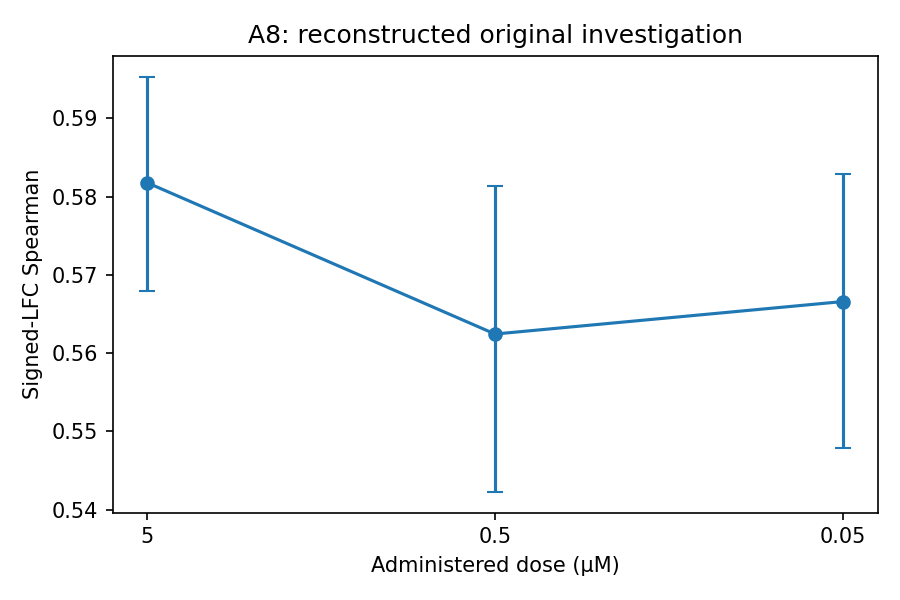

**A10 newly calculated results**

,fit,n,clusters,coefficient,ci95,draws,seed,design_columns,cluster_fixed_effect,axis_standardization
0,raw,2984,199,-0.016922,"[-0.025074142865619688, -0.009070434054279979]",10000,20260716,"[weakness, context=HOP62, context=HepG2/C3A, context=Hs 766T, context=PANC-1]",True,population SD on all analyzed rows
1,adjusted,2984,199,-0.016987,"[-0.024882634984298442, -0.009149234753400211]",10000,20260716,"[weakness, log_n_de, log_n_treated, log_n_control, context=HOP62, context=HepG2/C3A, context=Hs ...",True,population SD on all analyzed rows
2,same_example_reference / reference,2982,199,0.001724,"[-0.02180808701170072, 0.02526512794169945]",10000,20260716,"[weakness, context=HOP62, context=HepG2/C3A, context=Hs 766T, context=PANC-1]",True,population SD on all analyzed rows
3,same_example_reference / state,2982,199,-0.016927,"[-0.02508254995483016, -0.009073475272824537]",10000,20260716,"[weakness, context=HOP62, context=HepG2/C3A, context=Hs 766T, context=PANC-1]",True,population SD on all analyzed rows


,calculated
endpoint,-0.032045
endpoint_ci95,"[-0.048030122450856146, -0.016755780249608016]"
score_exclusions,1


,level,n,clusters,mean,ci_low,ci_high
0,1,995,199,0.473781,0.461385,0.486039
1,2,994,199,0.440905,0.422879,0.457033
2,3,995,199,0.441737,0.426148,0.455721


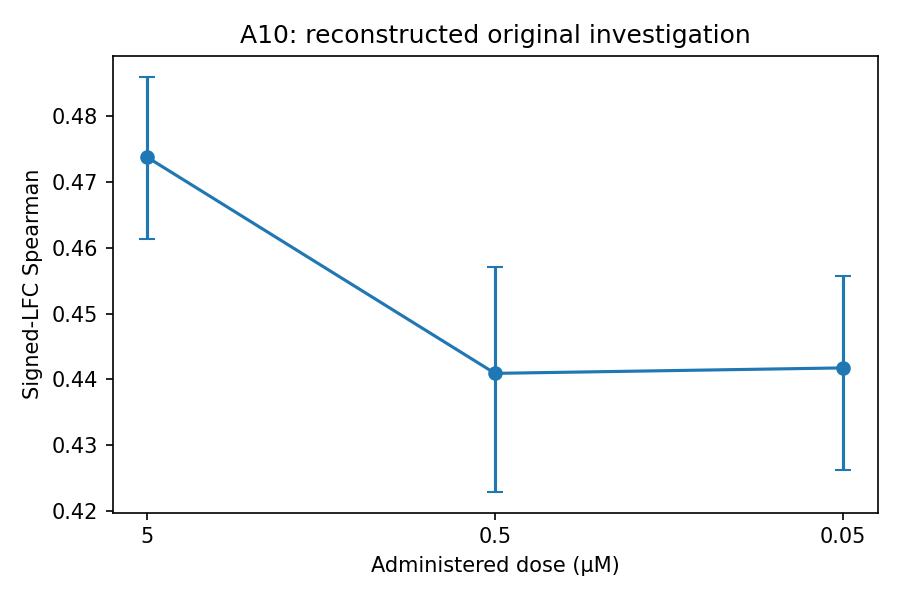

<IPython.core.display.JSON object>

,analysis,metric,historical,reconstructed,difference
0,A8,raw_slope,-0.010297,-0.010297,-3.295975e-17
1,A10,raw_slope,-0.016922,-0.016922,-6.591949e-17
2,A9,raw_slope,-0.000442,0.025264,2.570623e-02


Original recorded numbers are comparison targets; differences do not select the calculation method.


In [6]:
wf.source_functions(ROOT,'methods/common.py',['fisher','cluster_fit','curve'])
for name in ['A8','A10']:
    result=wf.read_json(ROOT,f'computed/tahoe/{name}_summary.json')
    display(Markdown('**'+name+' newly calculated results**'))
    wf.show_fits(result)
    display(pd.Series({k:result[k] for k in ['endpoint','endpoint_ci95','score_exclusions']}).to_frame('calculated'))
    display(wf.read_csv(ROOT,f'computed/tahoe/{name}_curve.csv'))
    wf.show_curve(ROOT,f'{name}_curve.png')
    if name=='A10':display(JSON(result['same_example_reference']))
wf.compare(ROOT,'computed/tahoe/historical_comparison.json')


## 7. Historical result and decision

The original sequence retired A7, judged A8 inconclusive, and accepted the frozen A10 low-dose result. Its same-example basal reference was classified as comparable by the original point-estimate rule. The historical disposition is preserved alongside the newly calculated results; this notebook does not issue a new certification.

In [7]:
wf.original_rows(ROOT,['A7','A8','A10'])
print('Original A10R interpretation: basal reference flat; point-estimate comparison within the documented ±0.02 band.')
print('See notebook04 for the original A9 checkpoint-specific mitochondrial investigation.')


,candidate_id,axis,status,decision_reason,next_action
8,A7,administered dose on ST-HVG few-shot,invalid,written success criterion had a sign contradiction detected after only schema/initial-row inspec...,retired without reinterpretation
9,A8,administered dose on ST-SE few-shot,inconclusive,"directional endpoint -0.01518 and adjusted slope -0.01406 CI [-0.02547,-0.00247], but frozen una...",single protocol rescue on unread ST-HVG zero-shot
11,A10,administered dose on ST-HVG zero-shot,confirmed,"2984 units/199 drugs; slope -0.01692 CI [-0.02539,-0.00908]; adjusted -0.01592 CI [-0.02380,-0.0...",certified; reference flat and point-estimate gate comparable


These are attributed original decisions, not new adjudications.
Original A10R interpretation: basal reference flat; point-estimate comparison within the documented ±0.02 band.
See notebook04 for the original A9 checkpoint-specific mitochondrial investigation.
